what we will cover today:

1. what is a general function/model?
2. give example of linear regression and limitations
3. what problem does NNs solve?
4. how does it do it? architecture
5. pros and cons
6. example


for the architecture:
1. input/output
2. hidden layer
3. random weights
4. one layer perceptron
5. multi layer perceptron
6. optimise the input for output by moving weights around
7. checking their losses then backpropagating them


hyperparameter selection
1. how many layers?
2. what optimisation function?
3. mse vs entropy

# What are Neural Networks?

> **How to use this notebook.** Run the cells top to bottom (`Shift+Enter`). Cells marked
> **🎛️ Try it** have sliders or values you are meant to change. Don't worry about the code
> details yet, the point of today is the *idea*. The code is here so you can poke at it.

## A function is a way to represent a relationship between input and output

$$y = f(x)$$

That's it. Something goes in ($x$), something comes out ($y$), and $f$ is the rule that connects them.

We are going to look at **three relationships** of increasing complexity:

| # | Input $x$ | Output $y$ | How we'll represent $f$ |
|---|---|---|---|
| 1 | height | weight | a straight line |
| 2 | time of day | electricity usage | a smooth curve |
| 3 | the pixels of an image | which digit is in it | ??? |

Keep one question in mind the whole way through: **what changes between these three?**

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, FloatLogSlider, IntSlider

rng = np.random.default_rng(42)

# --- a small, consistent visual style for every chart in this notebook ---
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": GREY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "legend.frameon": False,
})
print("ready ✔")

ready ✔


## 1. Relationship between height and weight

Taller people tend to weigh more. Not always, not exactly, but *on average*. Let's make up a sample of 120 people and look.

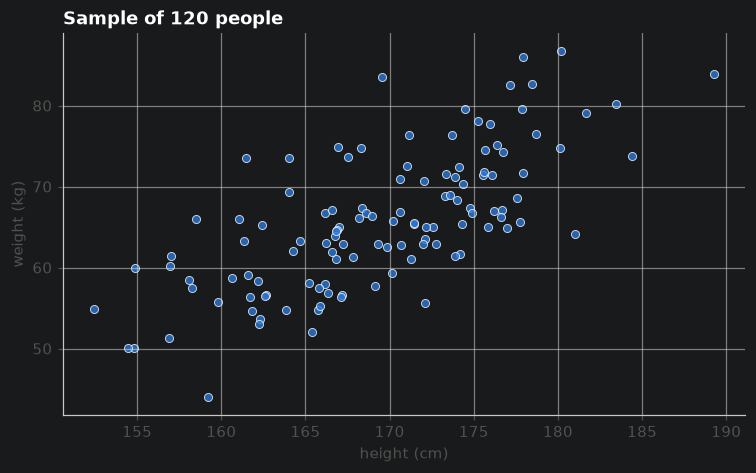

In [16]:
n = 120
height = rng.normal(loc=170, scale=9, size=n)                 # cm
weight = 0.95 * height - 95 + rng.normal(scale=6, size=n)     # kg, with natural scatter

fig, ax = plt.subplots()
ax.scatter(height, weight, s=28, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.6)
ax.set(xlabel="height (cm)", ylabel="weight (kg)", title="Sample of 120 people")
plt.show()

The simplest rule that captures "taller → heavier" is a **straight line**:

$$y = wx + b$$

where

- $y$ = weight (kg), the thing we want to **predict**
- $x$ = height (cm), the thing we **know**
- $w$ = the **weight** of the input *(confusingly also the word "weight", but here it means slope)*: how many kg each extra cm is worth
- $b$ = the **bias** (intercept): where the line sits when $x = 0$

Two numbers, $w$ and $b$, fully describe this function. We call them the **parameters**.

### 🎛️ Try it: fit the line by hand

Move the sliders and try to make the line go through the middle of the cloud. The number in the title is the
**mean squared error**: the average of (actual − predicted)² over all people. Smaller is better.

In [17]:
def plot_line(w=0.5, b=0.0, show_residuals=True):
    pred = w * height + b
    mse = np.mean((weight - pred) ** 2)
    xs = np.array([height.min() - 3, height.max() + 3])

    fig, ax = plt.subplots()
    if show_residuals:
        ax.vlines(height, weight, pred, color=ORANGE, alpha=0.35, linewidth=1)
    ax.scatter(height, weight, s=28, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.6)
    ax.plot(xs, w * xs + b, color=ORANGE, linewidth=2, label=f"y = {w:.2f}·x + {b:.0f}")
    ax.set(xlabel="height (cm)", ylabel="weight (kg)",
           ylim=(weight.min() - 10, weight.max() + 10),
           title=f"Mean squared error = {mse:,.1f}")
    ax.legend(loc="upper left")
    plt.show()

interact(plot_line,
         w=FloatSlider(value=0.5, min=0.0, max=2.0, step=0.01, description="w (slope)"),
         b=FloatSlider(value=0.0, min=-250, max=100, step=1, description="b (bias)"));

interactive(children=(FloatSlider(value=0.5, description='w (slope)', max=2.0, step=0.01), FloatSlider(value=0…

Doing that by hand is tedious. **Fitting a model** just means: let the computer search for the $w$ and $b$ with the smallest error.
For a straight line there is even a closed-form answer (ordinary least squares).

best w = 0.841 kg per cm
best b = -76.7 kg


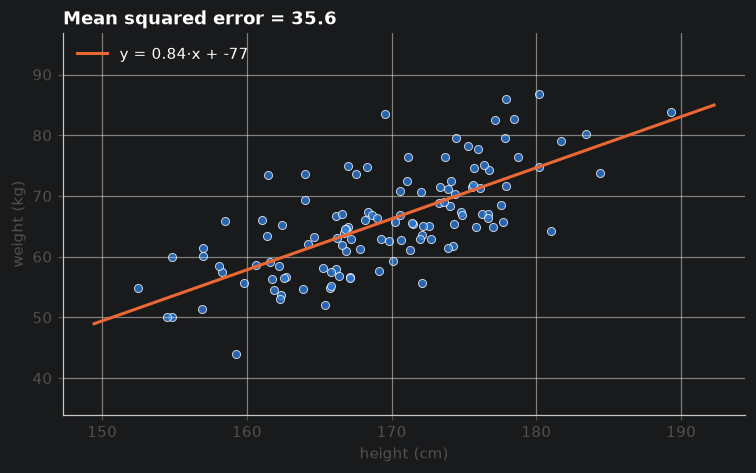

In [18]:
w_hat, b_hat = np.polyfit(height, weight, deg=1)   # least-squares straight line
print(f"best w = {w_hat:.3f} kg per cm")
print(f"best b = {b_hat:.1f} kg")
plot_line(w_hat, b_hat, show_residuals=False)

### What can we learn / infer?

- **Direction and strength of the relationship.** $w \approx 0.84$ means each extra centimetre of height comes with roughly 0.8 kg more weight, on average.
- **Prediction.** Plug in a height you have never seen (say 182 cm) and the function gives you a sensible weight.
- **Interpretability.** Two numbers. You can read them, explain them, argue about them.

### And what are the limits?

- The line is only good **where we have data**. At $x = 0$ it predicts a weight of about $-77$ kg. Garbage.
- It can only ever express *"more of this → proportionally more of that"*. If the real relationship bends, a line **cannot bend with it**.

That second limitation is exactly what the next example runs into.

## 2. Relationship between time and electricity usage

Here is one day of a household's electricity use, measured every 10 minutes.

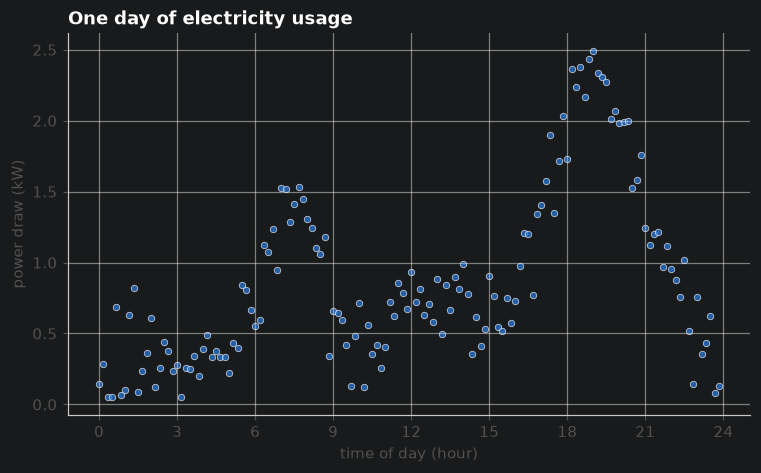

In [19]:
def bump(t, centre, width, amp):
    # a smooth hill centred at `centre` hours, `width` hours wide, `amp` kW tall
    return amp * np.exp(-0.5 * ((t - centre) / width) ** 2)

t = np.arange(0, 24, 10 / 60)                                   # hours, every 10 minutes
true_usage = (0.30                                              # fridge, router, standby...
              + bump(t, 7.5, 1.0, 1.2)                          # morning: kettle, shower, toast
              + bump(t, 13.0, 1.5, 0.4)                         # lunch
              + bump(t, 19.0, 1.8, 2.0))                        # evening: cooking, TV, heating
usage = true_usage + rng.normal(scale=0.18, size=t.size)        # what the meter actually reads
usage = np.clip(usage, 0.05, None)

fig, ax = plt.subplots()
ax.scatter(t, usage, s=18, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
ax.set(xlabel="time of day (hour)", ylabel="power draw (kW)", xticks=range(0, 25, 3),
       title="One day of electricity usage")
plt.show()

### First attempt: the straight line from before

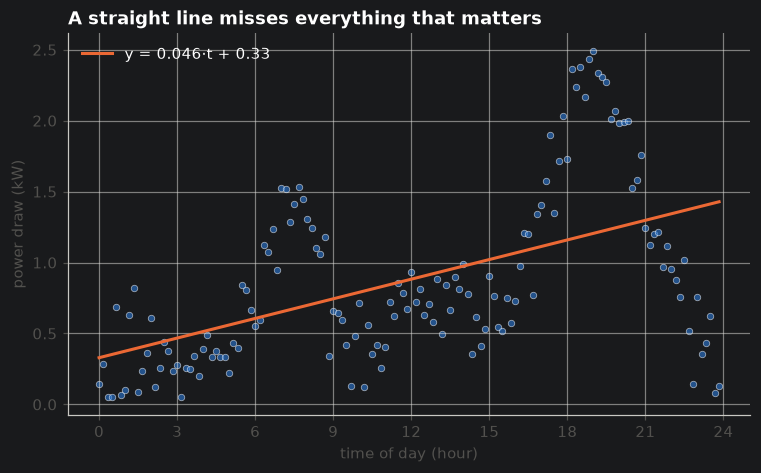

In [20]:
w_e, b_e = np.polyfit(t, usage, deg=1)

fig, ax = plt.subplots()
ax.scatter(t, usage, s=18, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.5)
ax.plot(t, w_e * t + b_e, color=ORANGE, linewidth=2, label=f"y = {w_e:.3f}·t + {b_e:.2f}")
ax.set(xlabel="time of day (hour)", ylabel="power draw (kW)", xticks=range(0, 25, 3),
       title="A straight line misses everything that matters")
ax.legend()
plt.show()

The line says "usage goes up slightly across the day". True, but useless: it misses breakfast and it misses dinner entirely.
The relationship between time and usage is **not a line**. It **bends**, twice.

So instead of forcing a shape onto the data, let's write the function as

$$y = \beta_0 + s(t)$$

where

- $y$ = power draw (kW)
- $t$ = time of day
- $\beta_0$ = a baseline level (the always-on load)
- $s(\cdot)$ = **a smooth curve whose shape we let the data decide**

This is a **Generalised Additive Model (GAM)**. Under the hood $s(t)$ is built from a few dozen small, bendy
building blocks (*splines*), each with its own parameter, and fitting the model means finding the mix of those blocks
that follows the data without chasing every noisy point.

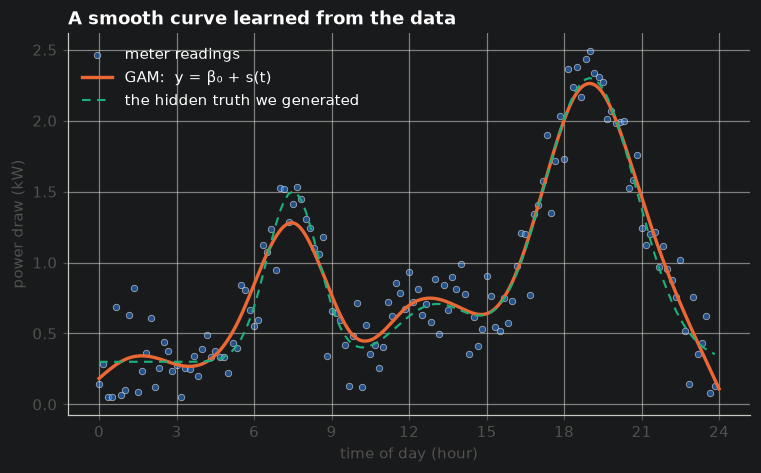

the line used 2 parameters; this GAM is using about 13 effective parameters


In [21]:
from pygam import LinearGAM, s

gam = LinearGAM(s(0, n_splines=25)).fit(t, usage)

t_grid = np.linspace(0, 24, 400)
fig, ax = plt.subplots()
ax.scatter(t, usage, s=18, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.5, label="meter readings")
ax.plot(t_grid, gam.predict(t_grid), color=ORANGE, linewidth=2.2, label="GAM:  y = β₀ + s(t)")
ax.plot(t, true_usage, color=AQUA, linewidth=1.4, linestyle=(0, (4, 3)), label="the hidden truth we generated")
ax.set(xlabel="time of day (hour)", ylabel="power draw (kW)", xticks=range(0, 25, 3),
       title="A smooth curve learned from the data")
ax.legend(loc="upper left")
plt.show()

print(f"the line used 2 parameters; this GAM is using about {gam.statistics_['edof']:.0f} effective parameters")

### 🎛️ Try it: how bendy should the curve be?

`lam` is the GAM's *smoothness penalty*. Tiny `lam` → the curve is allowed to wiggle through every point.
Huge `lam` → the curve is pressed flat until it becomes... a straight line again.

Somewhere in the middle it captures the real pattern and ignores the noise. (pygam picks this automatically with `gridsearch`, here you get to feel it.)

In [22]:
def plot_gam(lam=1.0):
    g = LinearGAM(s(0, n_splines=25, lam=lam)).fit(t, usage)
    fig, ax = plt.subplots()
    ax.scatter(t, usage, s=18, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.5)
    ax.plot(t_grid, g.predict(t_grid), color=ORANGE, linewidth=2.2)
    ax.set(xlabel="time of day (hour)", ylabel="power draw (kW)", xticks=range(0, 25, 3),
           ylim=(0, usage.max() + 0.3),
           title=f"lam = {lam:g}   →   ≈ {g.statistics_['edof']:.0f} effective parameters")
    plt.show()

interact(plot_gam, lam=FloatLogSlider(value=1, base=10, min=-4, max=6, step=0.25, description="lam"));

interactive(children=(FloatLogSlider(value=1.0, description='lam', max=6.0, min=-4.0, step=0.25), Output()), _…

### What can we learn / infer?

- **The shape itself is the insight.** Two peaks, the evening one bigger: that tells an energy company when the grid is stressed.
- **We never wrote the formula for the curve.** We gave the model flexible building blocks and a measure of error, and it found the shape.
- **The cost of flexibility is more parameters** and a new danger: fit too tightly and you learn the noise instead of the signal (*overfitting*). The `lam` slider is a knob that trades those off.

Notice though: this is still **one input** ($t$) and one output. What happens when the input is not one number, but hundreds?

## 3. Relationship between pixel colour and number

A handwritten digit, to a computer, is just a grid of numbers. This one is 28 × 28 pixels; each pixel holds a brightness between 0.0 (black) and 1.0 (white):

![a handwritten 3 shown as a 28x28 grid of brightness values](mnist_3.png)

So the input $x$ is not one number, it is **784 numbers** at once:

![pixel brightness values from 0.0 to 1.0](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/pixel-values.jpg)

And the output? We don't want "a number", we want **how confident the function is about each possible digit**.
Ten outputs, one per digit:

![the ten output neurons, one per digit](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/output-layer.jpg)

So the function we are after is

$$y_k = f_k(x_1, x_2, \dots, x_{784}) \qquad k = 0, 1, \dots, 9$$

where

- $x_1 \dots x_{784}$ = the brightness of every pixel
- $y_k$ = the **probability that the image is the digit $k$**
- the ten $y_k$ add up to 1

### Why can't we just write this formula down?

Try. What is the rule that says "these 784 brightnesses are a 3"? All of these are 3s:

![many different handwritten threes](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/three-3s.jpg)

Different thickness, slant, position, size, and yet a five-year-old gets them all right instantly. There is no
`if pixel[300] > 0.5 then ...` rule you could hand-write. The relationship between the pixels and the label is
**real, but enormously complicated**, and it only exists across *combinations* of pixels, never in a single one.

*(Images in this section from [3Blue1Brown's neural network lesson](https://www.3blue1brown.com/lessons/neural-networks).
For a live version where you draw a digit and watch the probabilities move, try
[this MLP visualiser](https://github.com/DFin/Neural-Network-Visualisation) or
[Adam Harley's 3D network](https://adamharley.com/nn_vis/).)*

## All three are functions that map inputs to outputs

| | 1. Height → weight | 2. Time → electricity | 3. Pixels → digit |
|---|---|---|---|
| inputs | 1 number | 1 number | 784 numbers |
| outputs | 1 number | 1 number | 10 probabilities |
| shape of $f$ | straight line | smooth curve | ??? |
| parameters | 2 | a few dozen | *tens of thousands and up* |
| who chose the shape? | we did | the data (within "smooth") | the data (within ???) |

Look down any column and it is the same object: $y = f(x)$. Something in, something out.

**Ultimately what changes is the complexity of the relationship**, and therefore how flexible $f$ has to be
and how many parameters it takes to describe it.

The `???` in the third column is what the rest of this session is about.

## The rise of neural networks

Problems of the third kind, many inputs with a tangled relationship to the output, used to be considered
too difficult or too complex to model. Two things changed that:

1. **Compute got dramatically faster and cheaper** (GPUs in particular, which are built for exactly the kind of maths these models do).
2. **We developed better algorithms** for training very flexible functions on very large amounts of data.

Put those together and suddenly we can model things we could not model before:

| Field | What is now possible | Where the network sits |
|---|---|---|
| **Robotics in surgery** | systems that analyse the surgical video feed in real time (segmenting tissue, tracking instruments) and assist teleoperated robots | pixels → "what is this and where is it" |
| **AI video generation** | a short text prompt → a clip in the style of a Hollywood scene, an animation or an Instagram reel, with plausible movement, lighting and physics | words → millions of pixels over time |
| **Coding assistants** | understand a task written in plain English, write the code, find the bug, ship the feature | words → words (that happen to be code) |
| **Video game bots** | agents that learn strategy and react to a changing environment. In 2019 OpenAI Five beat the reigning world champions at Dota 2 | game state → "which action next" |

Every one of these is, at its heart, a function from inputs to outputs. **Neural networks play a huge role in all of them**:
they are the family of functions flexible enough to represent these relationships.

## Towards an architecture

So far we have represented relationships as a **straight line** and as a **smooth curve**.

As the questions get harder, the models need to learn from **millions of input features**: pixels, words, sensor readings,
all interacting with each other. Neural networks provide the flexibility to do that.

But how do you actually **construct a mathematical function** capable of learning that? You cannot sit down and
write a formula with 784 inputs, and the "bendy building blocks" of the GAM were designed for one input at a time.

The answer turns out to be surprisingly humble: **take the straight line from example 1, add one small twist, and stack thousands of copies of it.**

Let's build it up.

## What is a weight and a bias?

We already met them. In $y = wx + b$:

- the **weight** $w$ says *how much the input matters*, and in which direction (positive: more $x$ → more $y$; negative: the opposite; near zero: ignore it)
- the **bias** $b$ *shifts the whole thing up or down*: the output you get when every input is zero

With many inputs it is the same idea, one weight per input, one bias in total:

$$z = w_1 x_1 + w_2 x_2 + \dots + w_{784} x_{784} + b$$

![weights on each input, summed](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/weights-blue.jpg)

A positive weight on a pixel means "if this pixel is bright, that's evidence *for*"; a negative weight means "evidence *against*".
The bias sets how much total evidence is needed before the unit gets excited:

![the bias shifts the threshold](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/bias.jpg)

### The one small twist

A weighted sum is still just a line (well, a flat plane in 784 dimensions). Stacking lines on lines only gives you... another line.
So after the sum, we pass $z$ through a simple **non-linear "squish" function**, called an *activation function*, such as the sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$:

![the sigmoid function](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/sigmoid.jpg)

That little unit, **weighted sum + bias → squish**, is a *neuron*. It is almost embarrassingly simple:

![a single neuron's equation annotated](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/annotated-equation.jpg)

### 🎛️ Try it: one neuron, one input

Move $w$ and $b$ and watch what one neuron can do with a single input. Notice: $w$ controls the **steepness** (and direction),
$b$ slides the step **left or right**.

In [23]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x_grid = np.linspace(-6, 6, 400)

def plot_neuron(w=1.0, b=0.0):
    fig, ax = plt.subplots()
    ax.plot(x_grid, sigmoid(1.0 * x_grid + 0.0), color="#c9c8c3", linewidth=1.4, label="w = 1, b = 0 (reference)")
    ax.plot(x_grid, sigmoid(w * x_grid + b), color=ORANGE, linewidth=2.2, label=f"σ({w:.1f}·x + {b:.1f})")
    ax.set(xlabel="input x", ylabel="output", ylim=(-0.05, 1.05), title="A single neuron")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    plt.show()

interact(plot_neuron,
         w=FloatSlider(value=1.0, min=-8, max=8, step=0.1, description="w"),
         b=FloatSlider(value=0.0, min=-10, max=10, step=0.1, description="b"));

interactive(children=(FloatSlider(value=1.0, description='w', max=8.0, min=-8.0), FloatSlider(value=0.0, descr…

### Why stacking these is powerful

One neuron gives you a soft step. **Two neurons, subtracted, give you a bump.** Add more and you can place bumps wherever you like,
at any width and height... which is exactly what the GAM's spline building blocks did, except now the blocks are *learned*
and they work for any number of inputs.

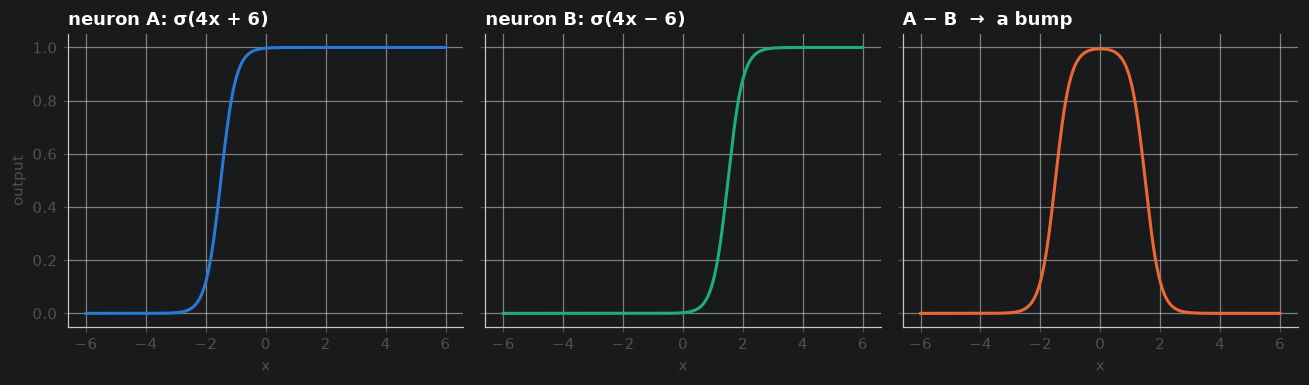

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)

n1 = sigmoid(4 * (x_grid + 1.5))          # steps up at x = -1.5
n2 = sigmoid(4 * (x_grid - 1.5))          # steps up at x = +1.5
axes[0].plot(x_grid, n1, color=BLUE, linewidth=2); axes[0].set_title("neuron A: σ(4x + 6)")
axes[1].plot(x_grid, n2, color=AQUA, linewidth=2); axes[1].set_title("neuron B: σ(4x − 6)")
axes[2].plot(x_grid, n1 - n2, color=ORANGE, linewidth=2); axes[2].set_title("A − B  →  a bump")
for ax in axes:
    ax.set(xlabel="x", ylim=(-0.05, 1.05))
axes[0].set_ylabel("output")
plt.tight_layout()
plt.show()

## What are neural networks?

A neural network is a function built by wiring up many of those simple neurons in **layers**. Because each neuron
has its own weights and bias, and every neuron feeds every neuron in the next layer, the whole thing has an enormous
number of adjustable parameters. Modern networks have billions.

That is the point: **they are functions with billions of ways to represent the relationship and co-dependency between
inputs**, so they can account for almost any pattern that exists in the data.

A network is defined by its **architecture**, the way it is constructed:

![input layer, hidden layers, output layer](NN.png)

1. **Input layer**: one node per input feature. For our digit: 784 nodes, one per pixel. For text: numbers representing words.
2. **Hidden layer(s)**: where the work happens. Each node is a neuron looking at *all* of the previous layer.
3. **Output layer**: one node per thing we want out. For our digit: 10 nodes, one per possible answer.

Input and output are self-explanatory and are whatever the problem needs. Inputs can be pixels, words, sound samples, sensor readings;
outputs can be the same kinds of things: a probability per class, a number, the next word, a new image.

### So what does the hidden layer do?

The hidden layer captures the **relationships between the inputs**, and between its own neurons. Each hidden neuron
combines all the inputs with its own weights, so it can respond to *patterns across many pixels at once*, something
no single pixel can tell you. The next hidden layer combines *those* patterns into bigger patterns, and so on:

![hypothesis: edges → loops and lines → digits](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/layer-hypothesis.jpg)

(That picture is a tidy story. Real networks learn messier features. The *mechanism* is right though: each layer
builds on combinations of what the previous layer found.)

Zoom out and the whole network is still just **one function** from the inputs to the outputs, with every weight and bias
as a knob on it:

![the network is a function](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/neural-network-function.jpg)

For a small 784 → 16 → 16 → 10 network that is 13,002 knobs:

![13,002 weights and biases](https://storage.googleapis.com/3blue1brown-website-bucket/lessons/2017/neural-networks/13002-blue.jpg)

## How does it do it?

Nobody sets 13,002 knobs by hand. Instead:

1. **Start with random weights and biases.** The network's output is garbage.
2. **Show it examples where we know the right answer** and measure how wrong it is (the *error*, like the mean squared error you minimised with the sliders).
3. **Nudge every weight and bias a tiny bit in the direction that reduces the error.** Repeat, many thousands of times.

In other words: by starting from random weights and biases, the network tries to infer the relationship between the
input and the output by **matching its outputs to the known answers**, and the relationship ends up encoded in the weights.
Step 3 is called *gradient descent*; the trick that tells us which direction to nudge each weight is *backpropagation*.
That is next session's topic. Today, let's just **watch it happen**.

We'll build the smallest possible network, 1 input → a handful of hidden neurons → 1 output, and let it learn the
electricity curve from example 2. Nothing is hidden in a library: it's a few dozen lines of NumPy.

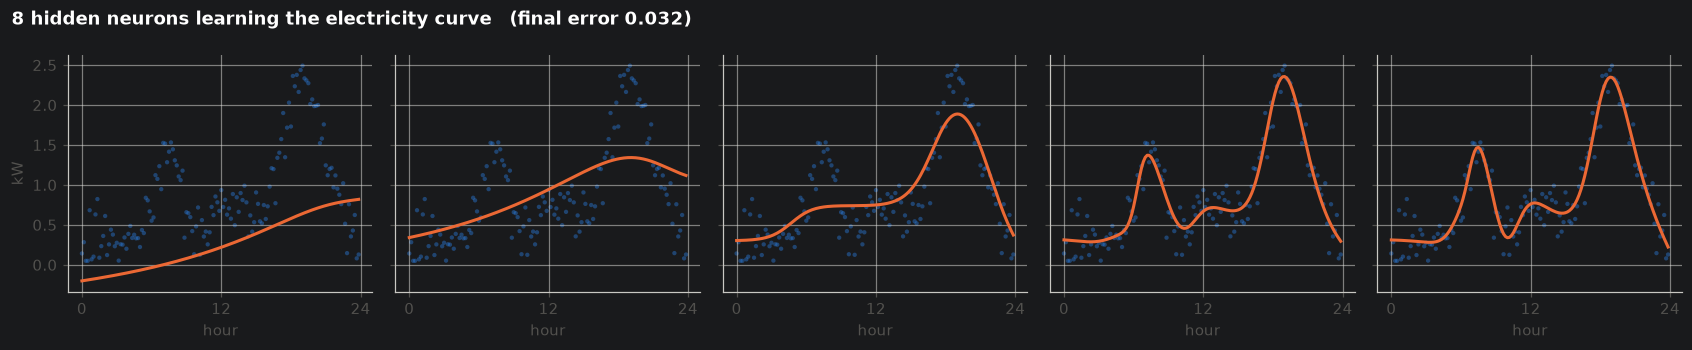

In [25]:
def train_tiny_network(n_hidden=8, steps=3000, lr=0.02, seed=0, snapshots=(0, 50, 200, 1000)):
    rng_ = np.random.default_rng(seed)
    x = (t - 12) / 12                       # scale time to [-1, 1]  (networks like small inputs)
    y = usage.reshape(-1, 1)
    X = x.reshape(-1, 1)

    # 1. random weights and biases ---------------------------------------------
    params = [rng_.normal(scale=2.0, size=(1, n_hidden)),     # W1: input  -> hidden
              rng_.normal(scale=2.0, size=(1, n_hidden)),     # b1
              rng_.normal(scale=0.5, size=(n_hidden, 1)),     # W2: hidden -> output
              np.zeros((1, 1))]                               # b2
    moments = [(np.zeros_like(p), np.zeros_like(p)) for p in params]

    def forward(X):
        W1, b1, W2, b2 = params
        h = np.tanh(X @ W1 + b1)            # hidden layer: weighted sum + bias, then squish
        return h @ W2 + b2, h               # output layer: weighted sum + bias

    history, losses = {}, []
    for step in range(1, steps + 1):
        pred, h = forward(X)
        err = pred - y
        losses.append(np.mean(err ** 2))    # 2. how wrong are we?
        if step - 1 in snapshots:
            history[step - 1] = pred.ravel().copy()

        # 3. work out, for every parameter, which direction reduces the error
        #    (this is backpropagation: next session's topic)
        W1, b1, W2, b2 = params
        g_out = 2 * err / len(y)
        g_h = (g_out @ W2.T) * (1 - h ** 2)
        grads = [X.T @ g_h, g_h.sum(0, keepdims=True), h.T @ g_out, g_out.sum(0, keepdims=True)]

        #    ...and nudge each parameter that way. "Adam" is a popular recipe that
        #    adapts the nudge size per parameter so training is quick and stable.
        for i, (p, g) in enumerate(zip(params, grads)):
            m, v = moments[i]
            m[:] = 0.9 * m + 0.1 * g
            v[:] = 0.999 * v + 0.001 * g ** 2
            m_hat, v_hat = m / (1 - 0.9 ** step), v / (1 - 0.999 ** step)
            p -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)

    history[steps] = forward(X)[0].ravel()
    return history, np.array(losses)


def plot_learning(n_hidden=8, steps=3000, seed=0):
    history, losses = train_tiny_network(n_hidden=n_hidden, steps=steps, seed=seed)
    stages = sorted(history)
    fig, axes = plt.subplots(1, len(stages), figsize=(3.1 * len(stages), 3.2), sharey=True)
    for ax, st in zip(axes, stages):
        ax.scatter(t, usage, s=8, color=BLUE, alpha=0.45, edgecolor="none")
        ax.plot(t, history[st], color=ORANGE, linewidth=2)
        ax.set(title=("random start" if st == 0 else f"after {st:,} nudges"), xticks=[0, 12, 24],
               xlabel="hour")
        ax.set_title(ax.get_title(), fontsize=10)
    axes[0].set_ylabel("kW")
    plt.suptitle(f"{n_hidden} hidden neurons learning the electricity curve   (final error {losses[-1]:.3f})",
                 x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_learning(n_hidden=8)

At the random start the curve is nonsense. Each panel to the right is the *same function* after its weights and biases
have been nudged a few hundred or thousand more times. Nobody told it where breakfast and dinner are. It found them by
reducing its error.

### 🎛️ Try it: how many hidden neurons does it take?

- With **1 or 2** hidden neurons the network can only draw one or two steps: not enough flexibility.
- With **8 or more** it has enough building blocks to place both peaks.
- Change the `seed` and the random start changes. Does it still get there?

In [26]:
interact(plot_learning,
         n_hidden=IntSlider(value=8, min=1, max=32, step=1, description="hidden"),
         steps=IntSlider(value=3000, min=500, max=8000, step=500, description="nudges"),
         seed=IntSlider(value=0, min=0, max=9, step=1, description="seed"));

interactive(children=(IntSlider(value=8, description='hidden', max=32, min=1), IntSlider(value=3000, descripti…

## Recap

- A **function** maps inputs to outputs: $y = f(x)$. Height → weight, time → electricity, pixels → digit are all the same kind of object.
- What changes between them is the **complexity of the relationship**, and therefore how flexible $f$ must be and how many **parameters** it needs.
- A **weight** says how much an input matters; a **bias** shifts the result. A **neuron** is a weighted sum plus bias, passed through a squish.
- A **neural network** is layers of neurons: input layer, hidden layer(s), output layer. The hidden layers capture relationships *between* inputs.
- It starts with **random weights and biases** and learns the relationship by repeatedly **nudging them to match known answers**.

**Next time:** how exactly do we know which way to nudge each weight? Loss functions, gradient descent and backpropagation,
built from scratch in NumPy (`neural_networks_from_scratch_numpy.ipynb`).

### Further watching
- 3Blue1Brown, [*But what is a neural network?*](https://www.3blue1brown.com/lessons/neural-networks) (the source of several figures above)
- OpenAI Five vs OG, [Dota 2 finals, April 2019](https://openai.com/index/openai-five-defeats-dota-2-world-champions/)